In [1]:
!pip install kagglehub

In [2]:
import pandas as pd
import numpy as np
import kagglehub
import os
from PIL import Image
from PIL import ImageOps
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Conv2D, Flatten, Dropout, MaxPooling2D,BatchNormalization
from tensorflow.keras.optimizers import Adam
import warnings



warnings.filterwarnings("ignore")

plt.style.use("ggplot")

In [3]:
# Download latest version

data_path = kagglehub.dataset_download("meowmeowmeowmeowmeow/gtsrb-german-traffic-sign")

print("Path to dataset files:", data_path)

100%|██████████| 612M/612M [00:21<00:00, 30.1MB/s]

Extracting files...


Path to dataset files: /root/.cache/kagglehub/datasets/meowmeowmeowmeowmeow/gtsrb-german-traffic-sign/versions/1


In [5]:
# Data path

dataset_path = os.path.join(data_path, "/root/.cache/kagglehub/datasets/meowmeowmeowmeowmeow/gtsrb-german-traffic-sign/versions/1")



# List files in the dataset directory

files = os.listdir(dataset_path)

print("Files in dataset directory:", files)

Files in dataset directory: ['Meta.csv', 'meta', 'test', 'train', 'Meta', 'Test.csv', 'Train.csv', 'Test', 'Train']


In [6]:
# Load the dataset

df = pd.read_csv(os.path.join(dataset_path, "Train.csv"))

df_test = pd.read_csv(os.path.join(dataset_path, "Test.csv"))

meta = pd.read_csv(os.path.join(dataset_path, "Meta.csv"))



print("Training dataset:")

print(df.head())



print("\nTest dataset:")

print(df_test.head())



print("\nMeta dataset:")

print(meta.head())

Training dataset:
   Width  Height  Roi.X1  Roi.Y1  Roi.X2  Roi.Y2  ClassId  \
0     27      26       5       5      22      20       20   
1     28      27       5       6      23      22       20   
2     29      26       6       5      24      21       20   
3     28      27       5       6      23      22       20   
4     28      26       5       5      23      21       20   

                             Path  
0  Train/20/00020_00000_00000.png  
1  Train/20/00020_00000_00001.png  
2  Train/20/00020_00000_00002.png  
3  Train/20/00020_00000_00003.png  
4  Train/20/00020_00000_00004.png  

Test dataset:
   Width  Height  Roi.X1  Roi.Y1  Roi.X2  Roi.Y2  ClassId            Path
0     53      54       6       5      48      49       16  Test/00000.png
1     42      45       5       5      36      40        1  Test/00001.png
2     48      52       6       6      43      47       38  Test/00002.png
3     27      29       5       5      22      24       33  Test/00003.png
4     60      

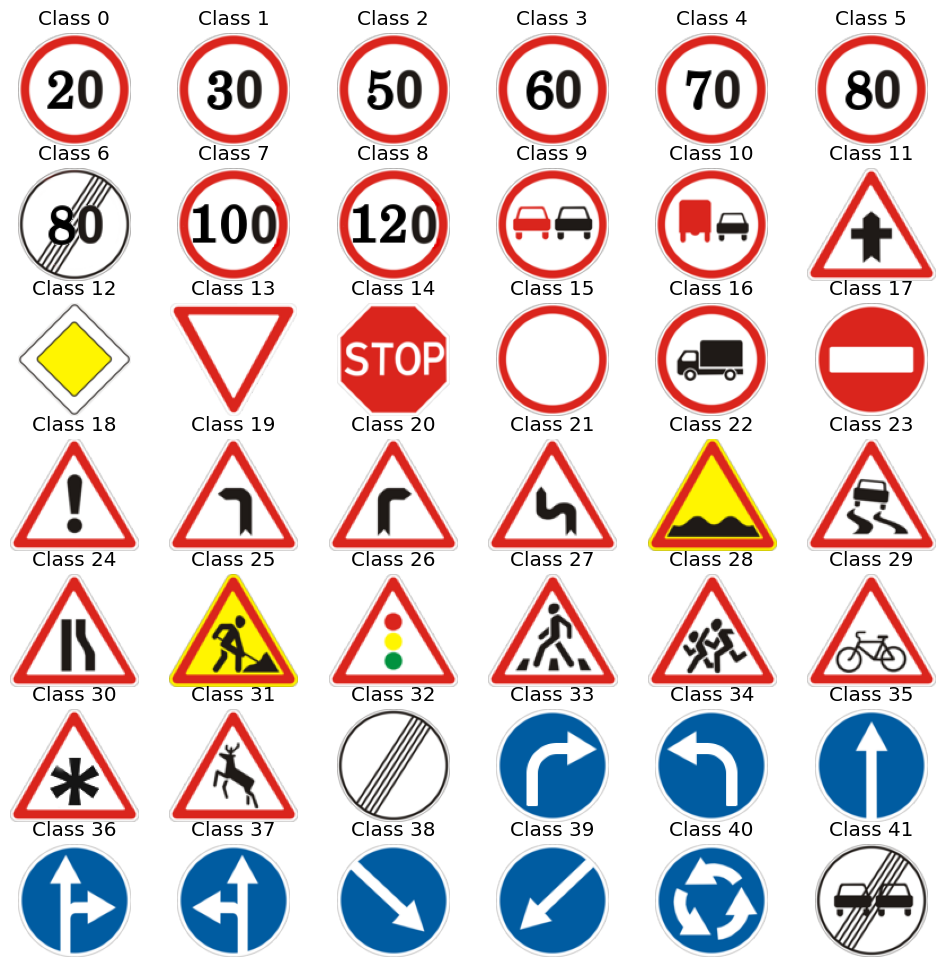

In [7]:
# Show all 42 images in meta dataset

# Rank the classes from 0 to 42 before displaying

meta_sorted = meta.sort_values(by="ClassId").reset_index(drop=True)

fig, axs = plt.subplots(7, 6, figsize=(12, 12))

for i in range(42):

    img_path = os.path.join(dataset_path, meta_sorted.iloc[i]["Path"])

    img = Image.open(img_path)

    axs[i // 6, i % 6].imshow(img)

    axs[i // 6, i % 6].axis("off")

    axs[i // 6, i % 6].set_title(f"Class {meta_sorted.iloc[i]['ClassId']}")

plt.show()

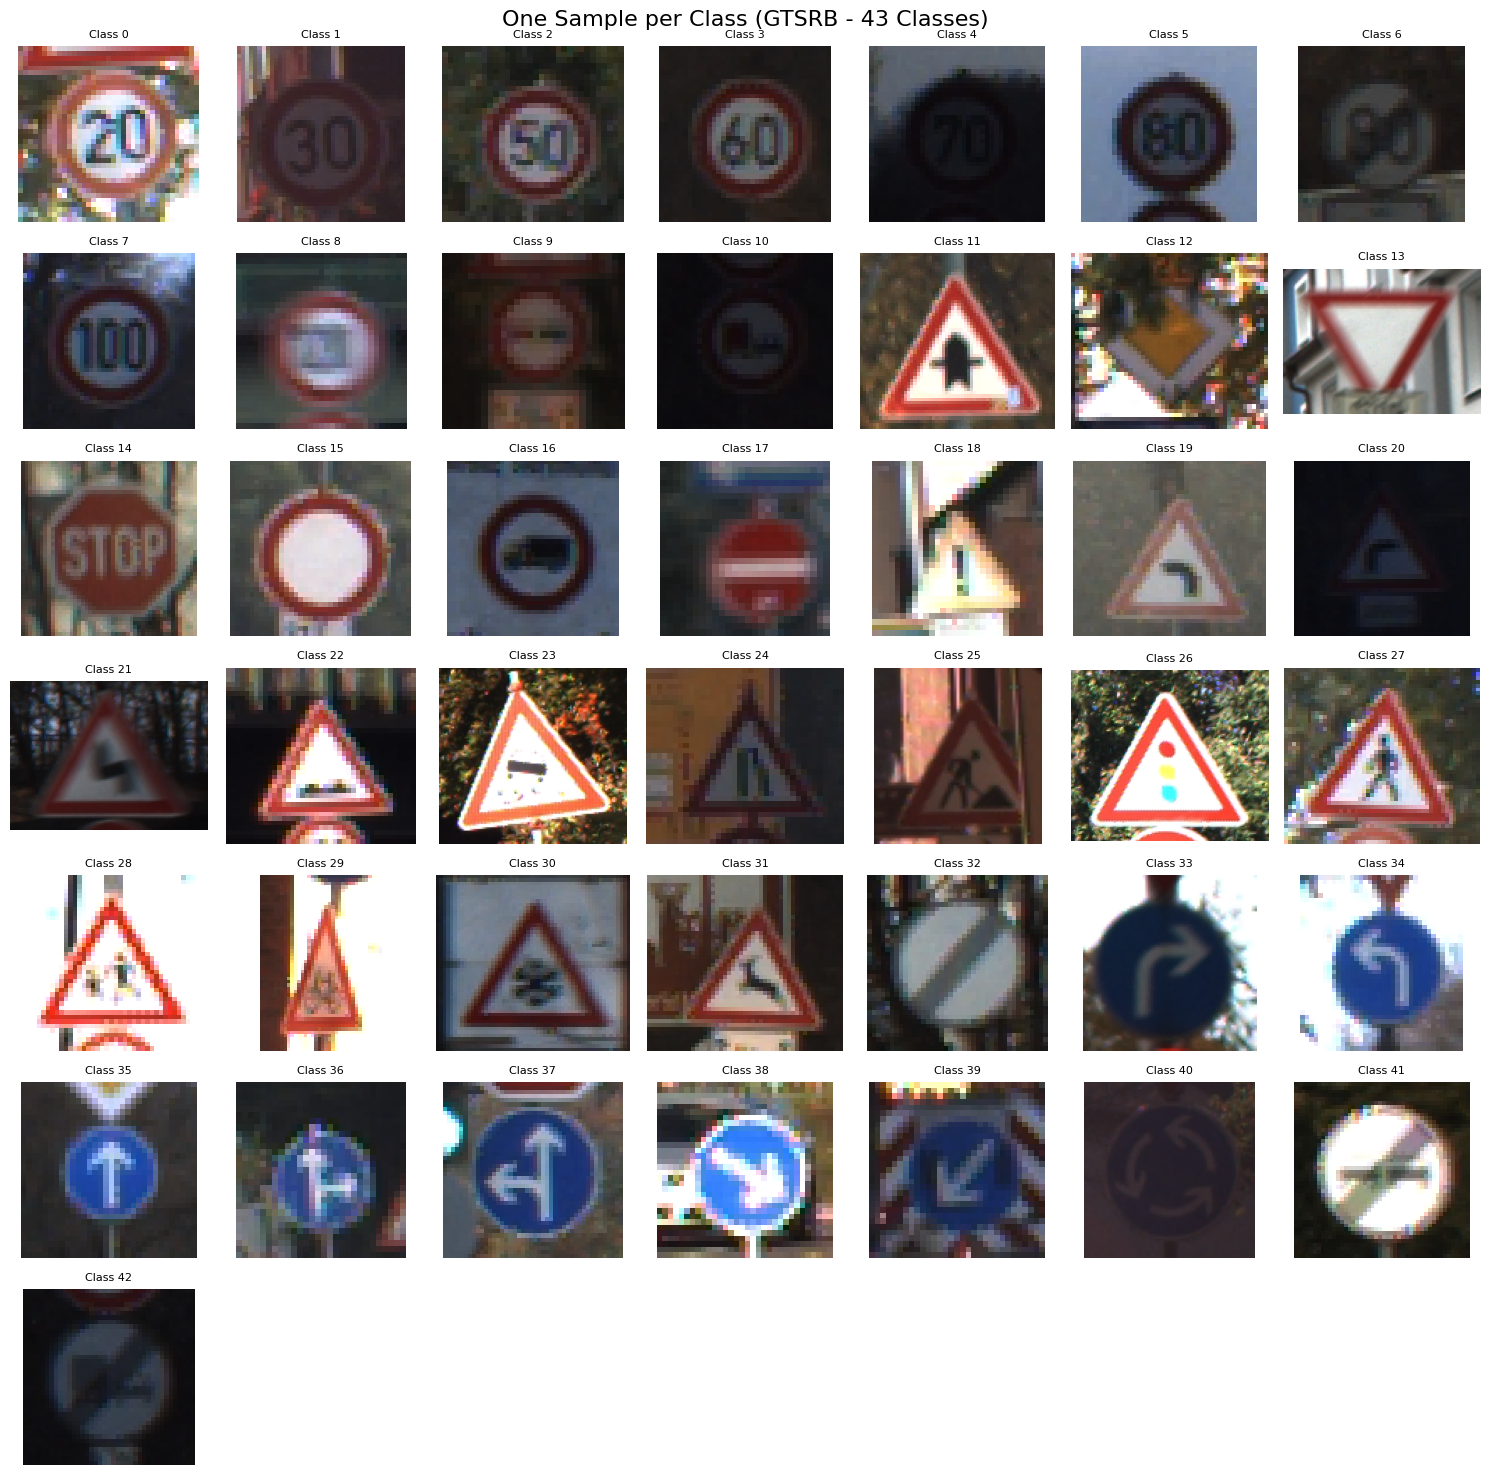

In [8]:
#Visualize sample images from each class

fig, axs = plt.subplots(7, 7, figsize=(15, 15))  # 7x7 = 49 subplots (we need 43)
axs = axs.ravel()  # Flatten the grid
for class_id in range(43):
    # Get one random sample from each class
    sample = df[df["ClassId"] == class_id].sample(1, random_state=1).iloc[0]
    img_path = os.path.join(dataset_path, sample["Path"])
    img = Image.open(img_path)

    axs[class_id].imshow(img)
    axs[class_id].axis("off")
    title = f"Class {class_id}"
    axs[class_id].set_title(title, fontsize=8)

# Turn off unused subplots (if any)
for i in range(43, len(axs)):
    axs[i].axis("off")

plt.suptitle("One Sample per Class (GTSRB - 43 Classes)", fontsize=16)
plt.tight_layout()
plt.show()

In [9]:
# Get the average and median width and height of the images in the training dataset

df["Width"] = df["Width"].astype(int)

df["Height"] = df["Height"].astype(int)



print("Average width:", df["Width"].mean())

print("Average height:", df["Height"].mean())

print("Median width:", df["Width"].median())

print("Median height:", df["Height"].median())

Average width: 50.83587951745773
Average height: 50.328929582493814
Median width: 43.0
Median height: 43.0


In [10]:
# Reshape the images to 43x43 pixels

def resize_image(img_path):

    img = Image.open(img_path)

    img = ImageOps.fit(img, (43, 43), Image.LANCZOS)

    return img



# Resize the images in the training dataset

df["ResizedPath"] = df["Path"].apply(lambda x: x.replace("Train", "ResizedTrain"))

os.makedirs(os.path.join(dataset_path, "ResizedTrain"), exist_ok=True)



for i in range(len(df)):

    img_path = os.path.join(dataset_path, df.iloc[i]["Path"])

    resized_img_path = os.path.join(dataset_path, df.iloc[i]["ResizedPath"])

    os.makedirs(os.path.dirname(resized_img_path), exist_ok=True)

    resized_img = resize_image(img_path)

    resized_img.save(resized_img_path)



# Resize the images in the test dataset

df_test["ResizedPath"] = df_test["Path"].apply(lambda x: x.replace("Test", "ResizedTest"))

os.makedirs(os.path.join(dataset_path, "ResizedTest"), exist_ok=True)



for i in range(len(df_test)):

    img_path = os.path.join(dataset_path, df_test.iloc[i]["Path"])

    resized_img_path = os.path.join(dataset_path, df_test.iloc[i]["ResizedPath"])

    os.makedirs(os.path.dirname(resized_img_path), exist_ok=True)

    resized_img = resize_image(img_path)

    resized_img.save(resized_img_path)



# Print out the shape of the resized images

img = Image.open(os.path.join(dataset_path, df.iloc[0]["ResizedPath"]))

print("Resized image shape:", np.array(img).shape)

Resized image shape: (43, 43, 3)


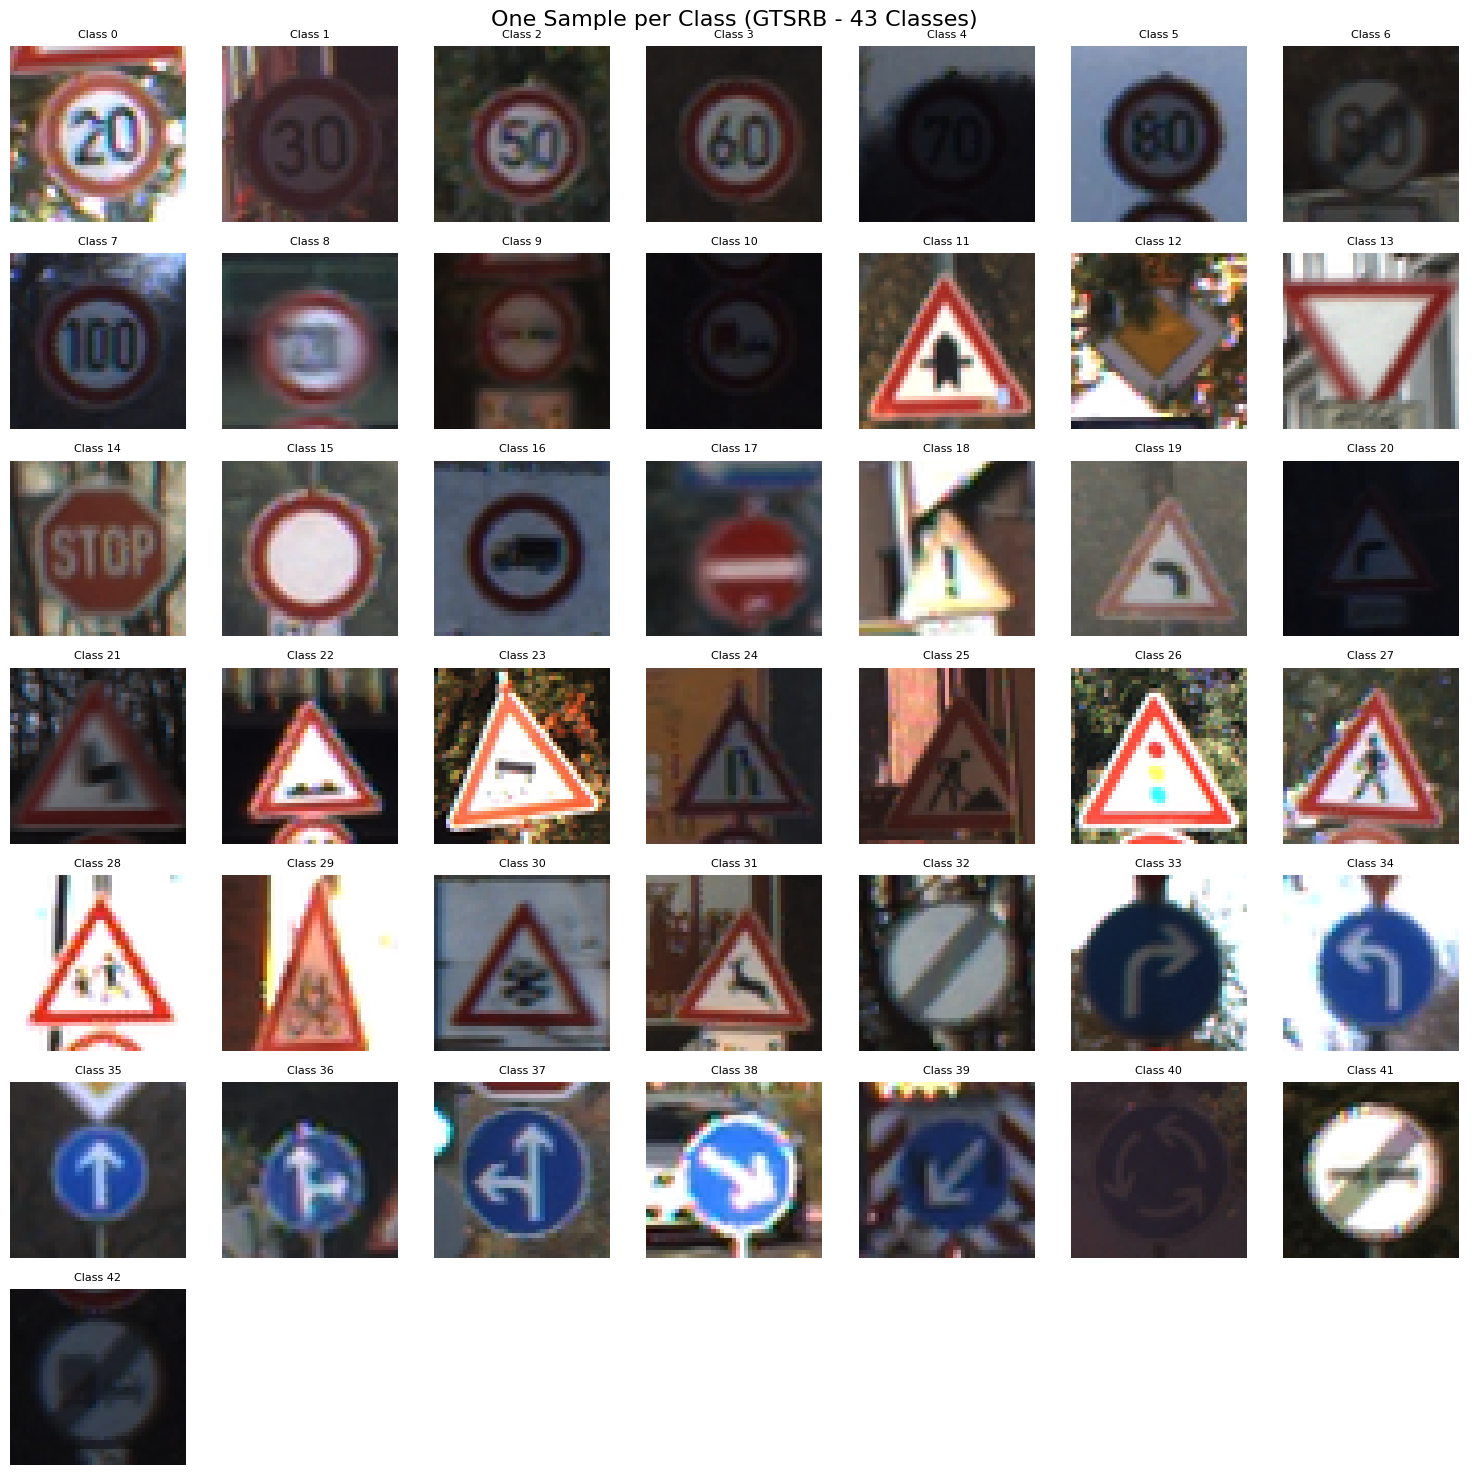

In [11]:


fig, axs = plt.subplots(7, 7, figsize=(15, 15))  # 7x7 = 49 subplots (we need 43)
axs = axs.ravel()  # Flatten the grid
for class_id in range(43):
    # Get one random sample from each class
    sample = df[df["ClassId"] == class_id].sample(1, random_state=1).iloc[0]
    img_path = os.path.join(dataset_path, sample["ResizedPath"])
    img = Image.open(img_path)

    axs[class_id].imshow(img)
    axs[class_id].axis("off")
    title = f"Class {class_id}"
    axs[class_id].set_title(title, fontsize=8)

# Turn off unused subplots (if any)
for i in range(43, len(axs)):
    axs[i].axis("off")

plt.suptitle("One Sample per Class (GTSRB - 43 Classes)", fontsize=16)
plt.tight_layout()
plt.show()

2-Split the  dataset

In [12]:
# Split dataset into training, validation and test sets

df_train, df_val = train_test_split(df, test_size=0.15, random_state=1)



print("Total training dataset shape:", df.shape)

print("Training dataset shape:", df_train.shape)

print("Validation dataset shape:", df_val.shape)

print("Total test dataset shape:", df_test.shape)

Total training dataset shape: (39209, 9)
Training dataset shape: (33327, 9)
Validation dataset shape: (5882, 9)
Total test dataset shape: (12630, 9)


In [13]:
# Encoding with label encoder
from sklearn.preprocessing import LabelEncoder

label_encoder = LabelEncoder()
label_encoder.fit(df["ClassId"])  # fits on 0–42

y_train = label_encoder.transform(df_train["ClassId"])
y_val = label_encoder.transform(df_val["ClassId"])
y_test = label_encoder.transform(df_test["ClassId"])

print("Label encoding applied.")

#Normalization (when loading images)

def load_and_normalize_image(img_path):
    img = Image.open(img_path)
    img = img.resize((43, 43))
    img_array = np.array(img).astype(np.float32) / 255.0  # Normalize to [0,1]
    return img_array

# Load datasets
X_train = np.array([load_and_normalize_image(os.path.join(data_path, p)) for p in df_train["ResizedPath"]])
X_val = np.array([load_and_normalize_image(os.path.join(data_path, p)) for p in df_val["ResizedPath"]])
X_test = np.array([load_and_normalize_image(os.path.join(data_path, p)) for p in df_test["ResizedPath"]])

print(f"Shapes after normalization:")
print(f"X_train: {X_train.shape}, y_train: {y_train.shape}")
print(f"X_val: {X_val.shape}, y_val: {y_val.shape}")
print(f"X_test: {X_test.shape}, y_test: {y_test.shape}")

Label encoding applied.
Shapes after normalization:
X_train: (33327, 43, 43, 3), y_train: (33327,)
X_val: (5882, 43, 43, 3), y_val: (5882,)
X_test: (12630, 43, 43, 3), y_test: (12630,)


In [14]:
# Build the  model
model = Sequential([
    Conv2D(32, (3, 3), activation='relu', input_shape=(43, 43, 3)),
    BatchNormalization(),
    MaxPooling2D((2, 2)),

    Conv2D(64, (3, 3), activation='relu'),
    BatchNormalization(),
    MaxPooling2D((2, 2)),
    Dropout(0.25),

    Conv2D(128, (3, 3), activation='relu'),
    BatchNormalization(),
    MaxPooling2D((2, 2)),
    Dropout(0.25),

    # Classifier head
    Flatten(),
    Dense(128, activation='relu'),
    BatchNormalization(),
    Dropout(0.5),

    # Output layer (43 classes)
    Dense(43, activation='softmax')
])

# Compile model with Adam optimizer and appropriate loss
model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss='sparse_categorical_crossentropy',  # because labels are integers (0-42)
    metrics=['accuracy']
)

# Display model architecture
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 41, 41, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 41, 41, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 20, 20, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 18, 18, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 18, 18, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 9, 9, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 9, 9, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 7, 7, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 7, 7, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 3, 3, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 3, 3, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1152)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 43)             │         5,547 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 247,787 (967.92 KB)

 Trainable params: 247,083 (965.17 KB)

 Non-trainable params: 704 (2.75 KB)

In [15]:
# Loads and processes images and labels in DataFrame

def load_images(df):

    images = []

    labels = []

    for i in range(len(df)):

        img_path = os.path.join(dataset_path, df.iloc[i]["ResizedPath"])

        img = load_and_normalize_image(img_path)

        images.append(img)

        labels.append(df.iloc[i]["ClassId"])

    return np.array(images), np.array(labels)



x_train, y_train = load_images(df_train)

x_val, y_val = load_images(df_val)

x_test, y_test = load_images(df_test)



# Train the model

model.fit(x_train, y_train, validation_data=(x_val, y_val), epochs=30)

Epoch 1/30
1042/1042 ━━━━━━━━━━━━━━━━━━━━ 86s 79ms/step - accuracy: 0.5069 - loss: 1.9810 - val_accuracy: 0.9820 - val_loss: 0.0995
Epoch 2/30
1042/1042 ━━━━━━━━━━━━━━━━━━━━ 142s 80ms/step - accuracy: 0.9507 - loss: 0.1807 - val_accuracy: 0.9748 - val_loss: 0.1206
Epoch 3/30
1042/1042 ━━━━━━━━━━━━━━━━━━━━ 139s 76ms/step - accuracy: 0.9756 - loss: 0.0890 - val_accuracy: 0.9917 - val_loss: 0.0400
Epoch 4/30
1042/1042 ━━━━━━━━━━━━━━━━━━━━ 85s 79ms/step - accuracy: 0.9829 - loss: 0.0605 - val_accuracy: 0.9832 - val_loss: 0.0595
Epoch 5/30
1042/1042 ━━━━━━━━━━━━━━━━━━━━ 142s 79ms/step - accuracy: 0.9828 - loss: 0.0601 - val_accuracy: 0.9935 - val_loss: 0.0295
Epoch 6/30
1042/1042 ━━━━━━━━━━━━━━━━━━━━ 142s 79ms/step - accuracy: 0.9870 - loss: 0.0421 - val_accuracy: 0.9855 - val_loss: 0.0471
Epoch 7/30
1042/1042 ━━━━━━━━━━━━━━━━━━━━ 146s 82ms/step - accuracy: 0.9868 - loss: 0.0464 - val_accuracy: 0.9973 - val_loss: 0.0117
Epoch 8/30
1042/1042 ━━━━━━━━━━━━━━━━━━━━ 142s 82ms/step - accuracy: 0.

In [16]:
# Test the model on the test dataset

test_loss, test_acc = model.evaluate(x_test, y_test)

print("Test accuracy:", test_acc)

395/395 ━━━━━━━━━━━━━━━━━━━━ 8s 19ms/step - accuracy: 0.9798 - loss: 0.0809
Test accuracy: 0.9813935160636902


<h2> Compare at least two different model variants. </h2>

<h3> Without BatchNormalization </h3>

In [17]:

model1 = Sequential([
    Conv2D(32, (3, 3), activation='relu', input_shape=(43, 43, 3)),
    MaxPooling2D((2, 2)),

    Conv2D(64, (3, 3), activation='relu'),
    MaxPooling2D((2, 2)),

    Conv2D(128, (3, 3), activation='relu'),
    MaxPooling2D((2, 2)),

    Flatten(),
    Dense(128, activation='relu'),
    Dropout(0.5),
    Dense(43, activation='softmax')
])

model1.compile(
    optimizer=Adam(learning_rate=0.001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model1.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_3 (Conv2D)               │ (None, 41, 41, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 20, 20, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 18, 18, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 9, 9, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 7, 7, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 3, 3, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 1152)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 43)             │         5,547 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 246,379 (962.42 KB)

 Trainable params: 246,379 (962.42 KB)

 Non-trainable params: 0 (0.00 B)

In [18]:
# Loads and processes images and labels in DataFrame

from tensorflow.keras.callbacks import EarlyStopping
# Define early stopping
early_stopping = EarlyStopping(
    monitor='val_loss',     # Metric to watch
    patience=5,             # Stop after 5 epochs with no improvement
    restore_best_weights=True  # Revert to the best model found
)
def load_images(df):

    images = []

    labels = []

    for i in range(len(df)):

        img_path = os.path.join(dataset_path, df.iloc[i]["ResizedPath"])

        img = load_and_normalize_image(img_path)

        images.append(img)

        labels.append(df.iloc[i]["ClassId"])

    return np.array(images), np.array(labels)



x_train, y_train = load_images(df_train)

x_val, y_val = load_images(df_val)

x_test, y_test = load_images(df_test)



# Train the model

model1.fit(x_train, y_train, validation_data=(x_val, y_val), epochs=30,callbacks=[early_stopping])

Epoch 1/30
1042/1042 ━━━━━━━━━━━━━━━━━━━━ 65s 61ms/step - accuracy: 0.3551 - loss: 2.3721 - val_accuracy: 0.9323 - val_loss: 0.2508
Epoch 2/30
1042/1042 ━━━━━━━━━━━━━━━━━━━━ 63s 60ms/step - accuracy: 0.8828 - loss: 0.3713 - val_accuracy: 0.9719 - val_loss: 0.1137
Epoch 3/30
1042/1042 ━━━━━━━━━━━━━━━━━━━━ 63s 60ms/step - accuracy: 0.9426 - loss: 0.1918 - val_accuracy: 0.9857 - val_loss: 0.0562
Epoch 4/30
1042/1042 ━━━━━━━━━━━━━━━━━━━━ 81s 60ms/step - accuracy: 0.9635 - loss: 0.1210 - val_accuracy: 0.9912 - val_loss: 0.0411
Epoch 5/30
1042/1042 ━━━━━━━━━━━━━━━━━━━━ 82s 60ms/step - accuracy: 0.9714 - loss: 0.0877 - val_accuracy: 0.9949 - val_loss: 0.0263
Epoch 6/30
1042/1042 ━━━━━━━━━━━━━━━━━━━━ 81s 59ms/step - accuracy: 0.9758 - loss: 0.0800 - val_accuracy: 0.9886 - val_loss: 0.0444
Epoch 7/30
1042/1042 ━━━━━━━━━━━━━━━━━━━━ 82s 59ms/step - accuracy: 0.9788 - loss: 0.0645 - val_accuracy: 0.9951 - val_loss: 0.0227
Epoch 8/30
1042/1042 ━━━━━━━━━━━━━━━━━━━━ 86s 63ms/step - accuracy: 0.9814 -

In [19]:
# Test the model on the test dataset

test_loss, test_acc = model1.evaluate(x_test, y_test)

print("Test accuracy:", test_acc)

395/395 ━━━━━━━━━━━━━━━━━━━━ 7s 17ms/step - accuracy: 0.9686 - loss: 0.2008
Test accuracy: 0.9673000574111938


<h3>Model3</h3>

In [20]:
model3 = Sequential([
    Conv2D(32, (3, 3), activation='relu', input_shape=(43, 43, 3)),
    BatchNormalization(),
    Conv2D(32, (3, 3), activation='relu'),
    MaxPooling2D((2, 2)),
    Dropout(0.25),

    Conv2D(64, (3, 3), activation='relu'),
    BatchNormalization(),
    Conv2D(64, (3, 3), activation='relu'),
    MaxPooling2D((2, 2)),
    Dropout(0.25),

    Conv2D(128, (3, 3), activation='relu'),
    BatchNormalization(),
    MaxPooling2D((2, 2)),
    Dropout(0.25),

    Flatten(),
    Dense(256, activation='relu'),  # Larger dense layer
    BatchNormalization(),
    Dropout(0.5),
    Dense(43, activation='softmax')
])

model3.compile(
    optimizer=Adam(learning_rate=0.001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model3.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_6 (Conv2D)               │ (None, 41, 41, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 41, 41, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 39, 39, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 19, 19, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 19, 19, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 17, 17, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 17, 17, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 15, 15, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_10 (Conv2D)              │ (None, 5, 5, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 5, 5, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_8 (MaxPooling2D)  │ (None, 2, 2, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 2, 2, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_7           │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 43)             │        11,051 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 283,723 (1.08 MB)

 Trainable params: 282,763 (1.08 MB)

 Non-trainable params: 960 (3.75 KB)

In [21]:
# Loads and processes images and labels in DataFrame

from tensorflow.keras.callbacks import EarlyStopping
# Define early stopping
early_stopping = EarlyStopping(
    monitor='val_loss',     # Metric to watch
    patience=5,             # Stop after 5 epochs with no improvement
    restore_best_weights=True  # Revert to the best model found
)

def load_images(df):

    images = []

    labels = []

    for i in range(len(df)):

        img_path = os.path.join(dataset_path, df.iloc[i]["ResizedPath"])

        img = load_and_normalize_image(img_path)

        images.append(img)

        labels.append(df.iloc[i]["ClassId"])

    return np.array(images), np.array(labels)



x_train, y_train = load_images(df_train)

x_val, y_val = load_images(df_val)

x_test, y_test = load_images(df_test)



# Train the model

model3.fit(x_train, y_train, validation_data=(x_val, y_val), epochs=30,callbacks=[early_stopping])

Epoch 1/30
1042/1042 ━━━━━━━━━━━━━━━━━━━━ 162s 153ms/step - accuracy: 0.3873 - loss: 2.5255 - val_accuracy: 0.9740 - val_loss: 0.1116
Epoch 2/30
1042/1042 ━━━━━━━━━━━━━━━━━━━━ 154s 148ms/step - accuracy: 0.9401 - loss: 0.2157 - val_accuracy: 0.9711 - val_loss: 0.1032
Epoch 3/30
1042/1042 ━━━━━━━━━━━━━━━━━━━━ 201s 147ms/step - accuracy: 0.9690 - loss: 0.1045 - val_accuracy: 0.9838 - val_loss: 0.0533
Epoch 4/30
1042/1042 ━━━━━━━━━━━━━━━━━━━━ 153s 147ms/step - accuracy: 0.9765 - loss: 0.0767 - val_accuracy: 0.9969 - val_loss: 0.0121
Epoch 5/30
1042/1042 ━━━━━━━━━━━━━━━━━━━━ 204s 148ms/step - accuracy: 0.9815 - loss: 0.0575 - val_accuracy: 0.9957 - val_loss: 0.0166
Epoch 6/30
1042/1042 ━━━━━━━━━━━━━━━━━━━━ 205s 151ms/step - accuracy: 0.9856 - loss: 0.0477 - val_accuracy: 0.9952 - val_loss: 0.0172
Epoch 7/30
1042/1042 ━━━━━━━━━━━━━━━━━━━━ 198s 147ms/step - accuracy: 0.9888 - loss: 0.0403 - val_accuracy: 0.9971 - val_loss: 0.0129
Epoch 8/30
1042/1042 ━━━━━━━━━━━━━━━━━━━━ 202s 147ms/step - ac

In [ ]:
# Test the model on the test dataset

test_loss, test_acc = model3.evaluate(x_test, y_test)

print("Test accuracy:", test_acc)

395/395 ━━━━━━━━━━━━━━━━━━━━ 4s 11ms/step - accuracy: 0.9831 - loss: 0.0702
Test accuracy: 0.9813935160636902
